# Lab 3 — Running a Single-Shot Detector, and Measuring Where It Fails

**Unit.** `fast_object_detection_networks` · **Duration.** 1 hour

A pretrained detector, 32 real images, and their ground-truth boxes. Nothing is trained
here: the lab is about what a trained single-shot detector gets right and what it gets
wrong, measured on numbers you produce yourself.

1. Run the detector and read what one forward pass returns.
2. Match its boxes to the ground truth by **IoU**, draw the two against each other, and
   compute the **localisation error** and the **label accuracy**.
3. Find the two places it fails: the confidence threshold, and small objects.

The unit claims that a single-shot detector localises loosely and classifies well, and
that small objects are its structural weakness. By the end of Exercise 3 you will have
measured both.

Work through the cells in order. Each cell marked **Your turn** is followed by a CHECK
cell that prints `[ok]` when you have it right.

## Setup

Provided. Downloads COCO128 (7 MB) and the YOLOv3-tiny weights (23 MB), both cached, then
draws four images with their ground-truth boxes so you can see what the annotations are.

On Colab the first cell installs `ultralytics`; running locally it does nothing.

In [1]:
# COLAB SETUP -- run this cell first.  Outside Colab it does nothing.
import importlib.util
import subprocess
import sys
import urllib.request

try:  # find_spec raises when the parent package is absent, so import instead
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Colab already ships torch and torchvision; install only what is missing.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "lightning", "torchmetrics", "ultralytics==8.3.228"], check=True)

# Fetch the lab's support module when it is not already beside the notebook.
if importlib.util.find_spec("lab3_utils") is None:
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/kenpu-uoit/csci4052u-machine-learning-2/main/labs/lab3/lab3_utils.py", "lab3_utils.py")
    print("downloaded lab3_utils.py")


downloaded lab3_utils.py


In [2]:
import time

import matplotlib.pyplot as plt
import torch

from lab3_utils import (
    CONF, N_IMAGES, SMALL_AREA,
    image_paths, image_size, load_ground_truth, load_model,
    draw_boxes, show_comparison, sweep_table,
    check_gt_to_xyxy, check_predictions, check_iou, check_match, check_figure,
    check_metrics, check_sweep, check_sweep_figure, check_scale,
)

torch.manual_seed(0)

IMAGES = image_paths(N_IMAGES)
model = load_model()
NAMES = model.names

print(f"{len(IMAGES)} images, {len(NAMES)} COCO classes, confidence threshold {CONF}")
print(f"first image: {IMAGES[0].name}, {image_size(IMAGES[0])[0]}x{image_size(IMAGES[0])[1]} px")
print(f"its annotation rows (class, cx, cy, w, h), normalised to [0, 1]:")
for row in load_ground_truth(IMAGES[0])[:3]:
    print("   ", NAMES[row[0]], tuple(round(v, 3) for v in row[1:]))

downloaded coco128.zip (7.0 MB) in 0.6s
downloaded yolov3-tinyu.pt (24.4 MB) in 0.4s
32 images, 80 COCO classes, confidence threshold 0.25
first image: 000000000009.jpg, 640x480 px
its annotation rows (class, cx, cy, w, h), normalised to [0, 1]:
    bowl (0.479, 0.689, 0.956, 0.596)
    bowl (0.737, 0.247, 0.499, 0.476)
    broccoli (0.637, 0.733, 0.494, 0.511)


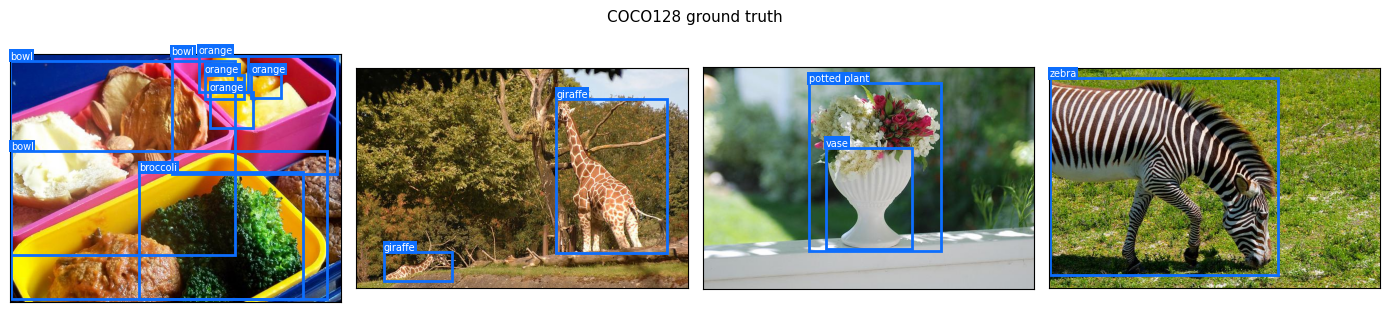

In [3]:
# What the ground truth looks like, drawn with the helper you will reuse in 2b.
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, path in zip(axes, IMAGES[:4]):
    w, h = image_size(path)
    boxes = [(c, (cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h)
             for c, cx, cy, bw, bh in load_ground_truth(path)]
    draw_boxes(ax, path, boxes, "#0d6efd", NAMES)
fig.suptitle("COCO128 ground truth", fontsize=11)
fig.tight_layout()
plt.show()

---

## Exercise 1 — One forward pass, and what comes out of it

*Outcome: formulate detection as one regression from image pixels to boxes and class
probabilities.*

### 1a · Ground truth into pixel corners — **Your turn**

COCO128 stores each object as `class cx cy w h`, where the four box numbers are the
**centre** and the **width and height**, each normalised to $[0, 1]$ against the image.
Everything downstream wants **corners in pixels**.

Write `gt_to_xyxy(rows, width, height)` returning a list of
`(class, x1, y1, x2, y2)`, keeping the class index as it is.

In [4]:
def gt_to_xyxy(rows, width, height):
    """YOLO-format rows -> (class, x1, y1, x2, y2) in pixels."""
    xyxy_rows = []
    for row in rows:
        cls_id, cx, cy, w, h = row

        # Shift centers by half the width/height, then scale by image dimensions
        x1 = (cx - w / 2.0) * width
        y1 = (cy - h / 2.0) * height
        x2 = (cx + w / 2.0) * width
        y2 = (cy + h / 2.0) * height

        xyxy_rows.append((int(cls_id), x1, y1, x2, y2))
    return xyxy_rows

In [5]:
check_gt_to_xyxy(gt_to_xyxy, IMAGES)

GROUND_TRUTH = [gt_to_xyxy(load_ground_truth(p), *image_size(p)) for p in IMAGES]

[ok] 1a: 209 ground-truth boxes, all inside their images.


### 1b · Run the detector — **Your turn**

Call the model on all 32 images at once and collect what it returns.

```python
results = model.predict([str(p) for p in IMAGES], device="cpu", conf=CONF, verbose=False)
```

Each `result` carries `result.boxes` with three parallel tensors: `.cls`, `.xyxy` and
`.conf`. Build `predictions` — **one list per image**, in the same order as `IMAGES`, of
`(class, x1, y1, x2, y2, score)` tuples with plain Python numbers.

Keep an image that found nothing as an empty list rather than dropping it; the lists must
line up with `GROUND_TRUTH`.

In [8]:
t0 = time.time()
predictions = []
results = model.predict([str(p) for p in IMAGES], device="cpu", conf=CONF, verbose=False)

for result in results:
    img_preds = []
    if result.boxes is not None:
        # Convert to CPU numpy arrays for safe iteration
        xyxy_coords = result.boxes.xyxy.cpu().numpy()
        confidences = result.boxes.conf.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy()

        for i in range(len(xyxy_coords)):
            x1, y1, x2, y2 = xyxy_coords[i]
            score = confidences[i]
            cls_id = int(classes[i])
            img_preds.append((cls_id, float(x1), float(y1), float(x2), float(y2), float(score)))

    predictions.append(img_preds)
elapsed = time.time() - t0

In [9]:
check_predictions(predictions, IMAGES, elapsed)

[ok] 1b: 144 boxes from 32 images, every score >= 0.25.
     693 ms per image on CPU.
     One evaluation of one network produced every box in each image: no
     proposal stage, and the cost does not grow with the number of objects.


---

## Exercise 2 — Matching, drawing, and the error profile

*Outcome: diagnose a single-shot detector's error profile and its structural limits.*

### 2a · Intersection over union — **Your turn**

$$\mathrm{IoU}(A, B) = \frac{|A \cap B|}{|A \cup B|}$$

Write `iou(box_a, box_b)` taking two `(x1, y1, x2, y2)` tuples. Two boxes that do not
touch must give exactly `0.0`, which means clamping each overlapping side at zero
**before** multiplying them.

In [10]:
def iou(box_a, box_b):
    """Intersection over union of two (x1, y1, x2, y2) boxes."""
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    # Calculate the intersection coordinates
    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    # Dimensions of intersection rectangle (clamped at 0.0)
    inter_w = max(0.0, ix2 - ix1)
    inter_h = max(0.0, iy2 - iy1)
    inter_area = inter_w * inter_h

    # Individual areas
    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)

    # Union area
    union_area = area_a + area_b - inter_area

    return inter_area / union_area if union_area > 0.0 else 0.0

In [11]:
check_iou(iou)

[ok] 2a: iou matches torchvision.ops.box_iou over 200 random pairs.


### 2b · Match, then look — **Your turn**

Two parts.

**The matcher.** Write `match(gts, preds, thr=0.5)` returning `(gt_index, pred_index, iou)`
triples. Walk the ground-truth boxes in order; each takes the **unused** prediction of
highest IoU with it, and the pair is kept only when that IoU reaches `thr`. A prediction
that has been taken is struck off — otherwise two overlapping objects both claim the same
box and recall is overstated.

The prediction tuples carry a score in position 5; `iou` wants corners, which are
positions 1 to 4 of both.

**The picture.** Then call
`show_comparison(IMAGES[:4], GROUND_TRUTH[:4], predictions[:4], NAMES)` and keep the
figure it returns as `fig`. Look at it before moving on: that is what an IoU of 0.8 and a
recall of under a half actually look like.

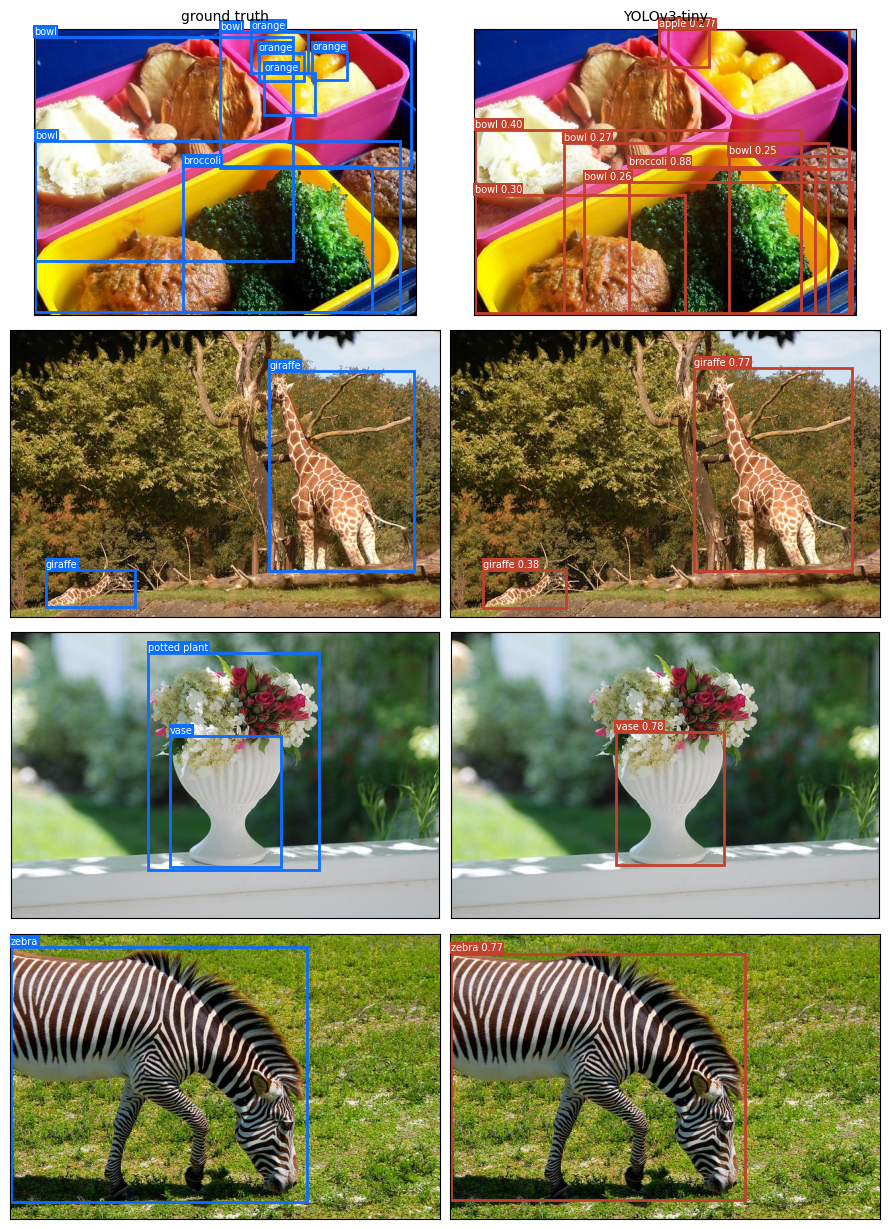

In [14]:
def match(gts, preds, thr=0.5):
    """Greedy IoU matching -> list of (gt_index, pred_index, iou)."""
    used_preds = set()
    matches = []

    for gi, g in enumerate(gts):
        best_iou = -1.0
        best_pi = -1

        for pi, p in enumerate(preds):
            if pi in used_preds:
                continue

            # iou expects coordinates from positions 1 to 4
            current_iou = iou(g[1:5], p[1:5])
            if current_iou > best_iou:
                best_iou = current_iou
                best_pi = pi

        if best_pi >= 0 and best_iou >= thr:
            used_preds.add(best_pi)
            matches.append((gi, best_pi, best_iou))

    return matches

# Generate the visualization and keep the figure reference
fig = show_comparison(IMAGES[:4], GROUND_TRUTH[:4], predictions[:4], NAMES)


In [15]:
check_match(match, GROUND_TRUTH, predictions)
check_figure(fig)

[ok] 2b: 97 of 209 ground-truth boxes matched, no prediction reused.
[ok] 2b: 4 rows, both panels drawn, boxes on every panel.


### 2c · Three numbers — **Your turn**

Over all 32 images, compute:

- **`recall`** — matched boxes divided by the number of ground-truth boxes.
- **`mean_iou`** — the mean IoU over matched pairs only. This is the localisation error:
  a perfect box scores 1.0.
- **`label_acc`** — of the matched pairs, the fraction whose predicted class equals the
  ground-truth class.

A matched pair is `(gi, pi, v)` from `match`; its ground-truth class is
`GROUND_TRUTH[image][gi][0]` and its predicted class is `predictions[image][pi][0]`.

In [16]:
total_gts = 0
total_matches = 0
sum_iou = 0.0
correct_labels = 0

for i in range(len(IMAGES)):
    gts = GROUND_TRUTH[i]
    preds = predictions[i]
    img_matches = match(gts, preds, thr=0.5)

    total_gts += len(gts)
    total_matches += len(img_matches)

    for gi, pi, v in img_matches:
        sum_iou += v

        gt_class = gts[gi][0]
        pred_class = preds[pi][0]
        if gt_class == pred_class:
            correct_labels += 1

recall = total_matches / total_gts if total_gts > 0 else 0.0
mean_iou = sum_iou / total_matches if total_matches > 0 else 0.0
label_acc = correct_labels / total_matches if total_matches > 0 else 0.0

print(f"recall         {recall:.1%}")
print(f"mean IoU       {mean_iou:.3f}")
print(f"label accuracy {label_acc:.1%}")

recall         46.4%
mean IoU       0.826
label accuracy 97.9%


In [17]:
check_metrics(recall, mean_iou, label_acc)

[ok] 2c: recall 46.4%, mean IoU 0.826, label accuracy 97.9%.

     Read those three together. The detector names what it finds almost
     perfectly (98%), draws the box loosely (IoU 0.83, not 1.0),
     and misses more than half the objects outright (54%).
     Localisation and recall are the problem; classification is not.
     That is the error profile the unit gives for a single-shot detector.


---

## Exercise 3 — Where it fails

*Outcome: choose a detector for a deployment constraint by reasoning about speed,
accuracy and object scale.*

### 3a · The confidence threshold — **Your turn**

Re-run the detector at each threshold in `THRESHOLDS` and recompute the three numbers.
Build `rows` as `(conf, n_predictions, recall, mean_iou, label_acc)`, one tuple per
threshold, in increasing order.

Then plot **recall** and **mean IoU** against the threshold on twin axes
(`ax2 = ax.twinx()`), and keep the figure as `sweep_fig`.

Four more passes over 32 images; about four seconds.

  conf   boxes   recall   mean IoU   label acc
  0.05     465    65.6%      0.803       94.9%
  0.10     286    60.3%      0.807       97.6%
  0.25     144    46.4%      0.826       97.9%
  0.50      71    30.1%      0.858      100.0%


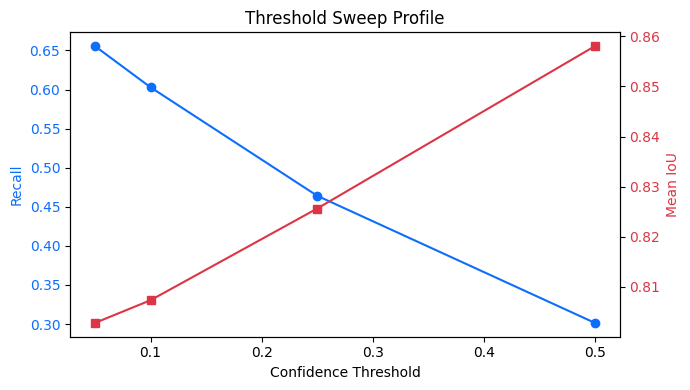

In [18]:
THRESHOLDS = [0.05, 0.10, 0.25, 0.50]

rows = []

for conf in THRESHOLDS:
    # 1. Re-run model inference on all images with the current threshold
    sweep_results = model.predict([str(p) for p in IMAGES], device="cpu", conf=conf, verbose=False)

    sweep_preds = []
    total_preds_count = 0
    for result in sweep_results:
        img_preds = []
        if result.boxes is not None:
            xyxy_coords = result.boxes.xyxy.cpu().numpy()
            confidences = result.boxes.conf.cpu().numpy()
            classes = result.boxes.cls.cpu().numpy()

            for i in range(len(xyxy_coords)):
                x1, y1, x2, y2 = xyxy_coords[i]
                score = confidences[i]
                cls_id = int(classes[i])
                img_preds.append((cls_id, float(x1), float(y1), float(x2), float(y2), float(score)))
                total_preds_count += 1
        sweep_preds.append(img_preds)

    # 2. Match ground truths to predictions and calculate metrics
    total_gts = 0
    total_matches = 0
    sum_iou = 0.0
    correct_labels = 0

    for i in range(len(IMAGES)):
        gts = GROUND_TRUTH[i]
        preds = sweep_preds[i]
        img_matches = match(gts, preds, thr=0.5)

        total_gts += len(gts)
        total_matches += len(img_matches)

        for gi, pi, v in img_matches:
            sum_iou += v
            # Compare class IDs (position 0 of the tuples)
            if gts[gi][0] == preds[pi][0]:
                correct_labels += 1

    c_recall = total_matches / total_gts if total_gts > 0 else 0.0
    c_mean_iou = sum_iou / total_matches if total_matches > 0 else 0.0
    c_label_acc = correct_labels / total_matches if total_matches > 0 else 0.0

    rows.append((conf, total_preds_count, c_recall, c_mean_iou, c_label_acc))

# 3. Create the required double-axis plot
sweep_fig, ax = plt.subplots(figsize=(7, 4))
ax2 = ax.twinx()

confs = [r[0] for r in rows]
recalls = [r[2] for r in rows]
ious = [r[3] for r in rows]

ax.plot(confs, recalls, color="#0d6efd", marker="o", label="Recall")
ax2.plot(confs, ious, color="#dc3545", marker="s", label="Mean IoU")

ax.set_xlabel("Confidence Threshold")
ax.set_ylabel("Recall", color="#0d6efd")
ax2.set_ylabel("Mean IoU", color="#dc3545")
ax.tick_params(axis="y", labelcolor="#0d6efd")
ax2.tick_params(axis="y", labelcolor="#dc3545")

plt.title("Threshold Sweep Profile")
plt.tight_layout()
sweep_table(rows)

In [19]:
check_sweep(rows)
check_sweep_figure(sweep_fig)

[ok] 3a: recall 65.6% -> 30.1% and mean IoU 0.803 -> 0.858 as the threshold rises.
     The threshold buys precision with recall; it cannot buy both.
[ok] 3a: both curves plotted.


### 3b · Small objects — **Your turn**

Split the ground-truth boxes by how much of the image they occupy. A box is **small** when
its area is below `SMALL_AREA` (5%) of the image area, and **large** otherwise.

At the original `CONF`, compute `small_recall` and `large_recall` — within each group, the
fraction of ground-truth boxes that found a match — along with the group sizes `n_small`
and `n_large`.

A ground-truth box counts as found when `match` returned a pair whose `gt_index` is its
index.

In [20]:
n_small = 0
n_large = 0
small_found = 0
large_found = 0

for i, path in enumerate(IMAGES):
    w, h = image_size(path)
    img_area = w * h

    gts = GROUND_TRUTH[i]
    preds = predictions[i]

    # Identify which ground-truth box indices successfully found a prediction match
    img_matches = match(gts, preds, thr=0.5)
    matched_gt_indices = {gi for gi, pi, v in img_matches}

    for gi, gt in enumerate(gts):
        # Calculate absolute pixel area of the ground truth box: (x2 - x1) * (y2 - y1)
        ax1, ay1, ax2, ay2 = gt[1:5]
        box_area = (ax2 - ax1) * (ay2 - ay1)

        # Categorize the box size based on whether it covers less than SMALL_AREA (5%) of the image area
        if box_area < (SMALL_AREA * img_area):
            n_small += 1
            if gi in matched_gt_indices:
                small_found += 1
        else:
            n_large += 1
            if gi in matched_gt_indices:
                large_found += 1

# Calculate the split recall metrics
small_recall = small_found / n_small if n_small > 0 else 0.0
large_recall = large_found / n_large if n_large > 0 else 0.0

print(f"small (<{SMALL_AREA:.0%} of the image): {small_recall:.1%} of {n_small}")
print(f"large:                      {large_recall:.1%} of {n_large}")

small (<5% of the image): 29.1% of 141
large:                      82.4% of 68


In [21]:
check_scale(small_recall, large_recall, n_small, n_large)

[ok] 3b: recall 29.1% on 141 small objects against 82.4% on 68 large ones, a factor of 2.8.

     The detector predicts from a coarse top-layer feature map, which carries
     little signal about a small object. This is the weakness SSD answered with
     prediction layers at several resolutions, and the reason the unit treats
     object scale as a design question rather than a detail.


---

## What this lab covered, and what it did not

Measured, on your own numbers:

- **One forward pass** turns an image into every box it contains, with no proposal stage,
  at a cost that does not grow with the number of objects.
- **The error profile**: the labels are almost always right, the boxes are loose, and more
  than half the objects are missed entirely. Localisation and recall are where a
  single-shot detector loses, not classification.
- **The confidence threshold** trades recall against precision and cannot improve both.
- **Object scale** is the structural limit: small objects are found at a fraction of the
  rate of large ones, because the map predictions are read from is too coarse to carry
  them.

The model here is `yolov3-tinyu.pt` — YOLOv3-tiny as Ultralytics publishes it, with an
anchor-free head retrofitted.